## This notebooks is a working notebook to test code for the final project

### We can create a separate, clean notebook later for submission if needed

# Load necessary Packages

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load data

In [18]:
url = 'https://raw.githubusercontent.com/kderosia31/final_project/refs/heads/main/data/marathon_results_2017.csv'
df1 = pd.read_csv(url)

# Clean data

In [19]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 26410 entries, 0 to 26409
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Unnamed: 0     26410 non-null  int64
 1   Bib            26410 non-null  str  
 2   Name           26410 non-null  str  
 3   Age            26410 non-null  int64
 4   M/F            26410 non-null  str  
 5   City           26410 non-null  str  
 6   State          22815 non-null  str  
 7   Country        26410 non-null  str  
 8   Citizen        1254 non-null   str  
 9   Unnamed: 9     91 non-null     str  
 10  5K             26410 non-null  str  
 11  10K            26410 non-null  str  
 12  15K            26410 non-null  str  
 13  20K            26410 non-null  str  
 14  Half           26410 non-null  str  
 15  25K            26410 non-null  str  
 16  30K            26410 non-null  str  
 17  35K            26410 non-null  str  
 18  40K            26410 non-null  str  
 19  Pace           

In [3]:
df1.head()

,Unnamed: 0,Bib,Name,Age,M/F,City,State,Country,Citizen,Unnamed: 9,...,25K,30K,35K,40K,Pace,Proj Time,Official Time,Overall,Gender,Division
0,0,11,"Kirui, Geoffrey",24,M,Keringet,NaN,KEN,NaN,NaN,...,1:16:59,1:33:01,1:48:19,2:02:53,0:04:57,-,2:09:37,1,1,1
1,1,17,"Rupp, Galen",30,M,Portland,OR,USA,NaN,NaN,...,1:16:59,1:33:01,1:48:19,2:03:14,0:04:58,-,2:09:58,2,2,2
2,2,23,"Osako, Suguru",25,M,Machida-City,NaN,JPN,NaN,NaN,...,1:17:00,1:33:01,1:48:31,2:03:38,0:04:59,-,2:10:28,3,3,3
3,3,21,"Biwott, Shadrack",32,M,Mammoth Lakes,CA,USA,NaN,NaN,...,1:17:00,1:33:01,1:48:58,2:04:35,0:05:03,-,2:12:08,4,4,4
4,4,9,"Chebet, Wilson",31,M,Marakwet,NaN,KEN,NaN,NaN,...,1:16:59,1:33:01,1:48:41,2:05:00,0:05:04,-,2:12:35,5,5,5


Looks like some unnamed columns and missing values are present. Specifically, the first and 10th columns seem problematic. THe first column is full but unnamed. The 10th column is unnamed and nearly empty (only 91 values). Also the durations for the different race checkpoints are strings, not times. Will need to convert them

In [8]:
df1.iloc[:,0]

0            0
1            1
2            2
3            3
4            4
         ...  
26405    26405
26406    26406
26407    26407
26408    26408
26409    26409
Name: Unnamed: 0, Length: 26410, dtype: int64

First column seems like row numbers, don't need. Will remove and check below

In [12]:
df1 = df1.drop(df1.columns[[0]], axis = 1)

In [14]:
df1.head()

,Bib,Name,Age,M/F,City,State,Country,Citizen,Unnamed: 9,5K,...,25K,30K,35K,40K,Pace,Proj Time,Official Time,Overall,Gender,Division
0,11,"Kirui, Geoffrey",24,M,Keringet,NaN,KEN,NaN,NaN,0:15:25,...,1:16:59,1:33:01,1:48:19,2:02:53,0:04:57,-,2:09:37,1,1,1
1,17,"Rupp, Galen",30,M,Portland,OR,USA,NaN,NaN,0:15:24,...,1:16:59,1:33:01,1:48:19,2:03:14,0:04:58,-,2:09:58,2,2,2
2,23,"Osako, Suguru",25,M,Machida-City,NaN,JPN,NaN,NaN,0:15:25,...,1:17:00,1:33:01,1:48:31,2:03:38,0:04:59,-,2:10:28,3,3,3
3,21,"Biwott, Shadrack",32,M,Mammoth Lakes,CA,USA,NaN,NaN,0:15:25,...,1:17:00,1:33:01,1:48:58,2:04:35,0:05:03,-,2:12:08,4,4,4
4,9,"Chebet, Wilson",31,M,Marakwet,NaN,KEN,NaN,NaN,0:15:25,...,1:16:59,1:33:01,1:48:41,2:05:00,0:05:04,-,2:12:35,5,5,5


Convert times from string to time delta

In [21]:
time_cols = ['5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Pace', 'Proj Time', 'Official Time']
df1[time_cols] = df1[time_cols].apply(pd.to_timedelta, errors = 'coerce')

In [24]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 26410 entries, 0 to 26409
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype          
---  ------         --------------  -----          
 0   Unnamed: 0     26410 non-null  int64          
 1   Bib            26410 non-null  str            
 2   Name           26410 non-null  str            
 3   Age            26410 non-null  int64          
 4   M/F            26410 non-null  str            
 5   City           26410 non-null  str            
 6   State          22815 non-null  str            
 7   Country        26410 non-null  str            
 8   Citizen        1254 non-null   str            
 9   Unnamed: 9     91 non-null     str            
 10  5K             26385 non-null  timedelta64[us]
 11  10K            26356 non-null  timedelta64[us]
 12  15K            26391 non-null  timedelta64[us]
 13  20K            26377 non-null  timedelta64[us]
 14  Half           26393 non-null  timedelta64[us]
 15  25K          

Investigate the 10th column with a lot of blanks

In [31]:
print(df1['Unnamed: 9'].unique())

<ArrowStringArray>
[nan, 'VI', 'MI']
Length: 3, dtype: str


Not sure what VI and MI are. Nothing in the source of the data explains this. Can likely remove

# Exploratory Data Analysis

## Does pacing vary depending on the country the runner is from?

Group athletes by country, calculate the mean times at each checkpoint, and plot them.

In [25]:
checkpoints = ['5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K']
country_averages = df1.groupby('Country')[checkpoints].mean()
country_averages.head()

,5K,10K,15K,20K,Half,25K,30K,35K,40K
Country,,,,,,,,,
ALG,0 days 00:25:19,0 days 00:48:40.500000,0 days 01:12:37.500000,0 days 01:37:12.500000,0 days 01:42:36,0 days 02:03:59,0 days 02:31:29.500000,0 days 03:00:45,0 days 03:30:51.500000
AND,0 days 00:22:40,0 days 00:45:41,0 days 01:09:41,0 days 01:34:38,0 days 01:39:53,0 days 01:59:49,0 days 02:26:44,0 days 02:56:59,0 days 03:28:02
ARG,0 days 00:24:26.222222,0 days 00:48:52.500000,0 days 01:13:29.861111,0 days 01:38:49.583333,0 days 01:44:20.083333,0 days 02:05:07.388888,0 days 02:33:07,0 days 03:02:45.777777,0 days 03:32:29.916666
AUS,0 days 00:24:22.952879,0 days 00:48:52.612565,0 days 01:13:50.534031,0 days 01:40:02.835978,0 days 01:45:32.125654,0 days 02:06:59.652631,0 days 02:35:41.507853,0 days 03:06:12.853403,0 days 03:36:16.863874
AUT,0 days 00:26:01.500000,0 days 00:51:53.272727,0 days 01:18:00.636363,0 days 01:44:54.409090,0 days 01:50:42.318181,0 days 02:12:59.454545,0 days 02:42:41.909090,0 days 03:13:54.772727,0 days 03:44:49.500000


C:\Users\kderosia\AppData\Local\Temp\ipykernel_29924\3560442210.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


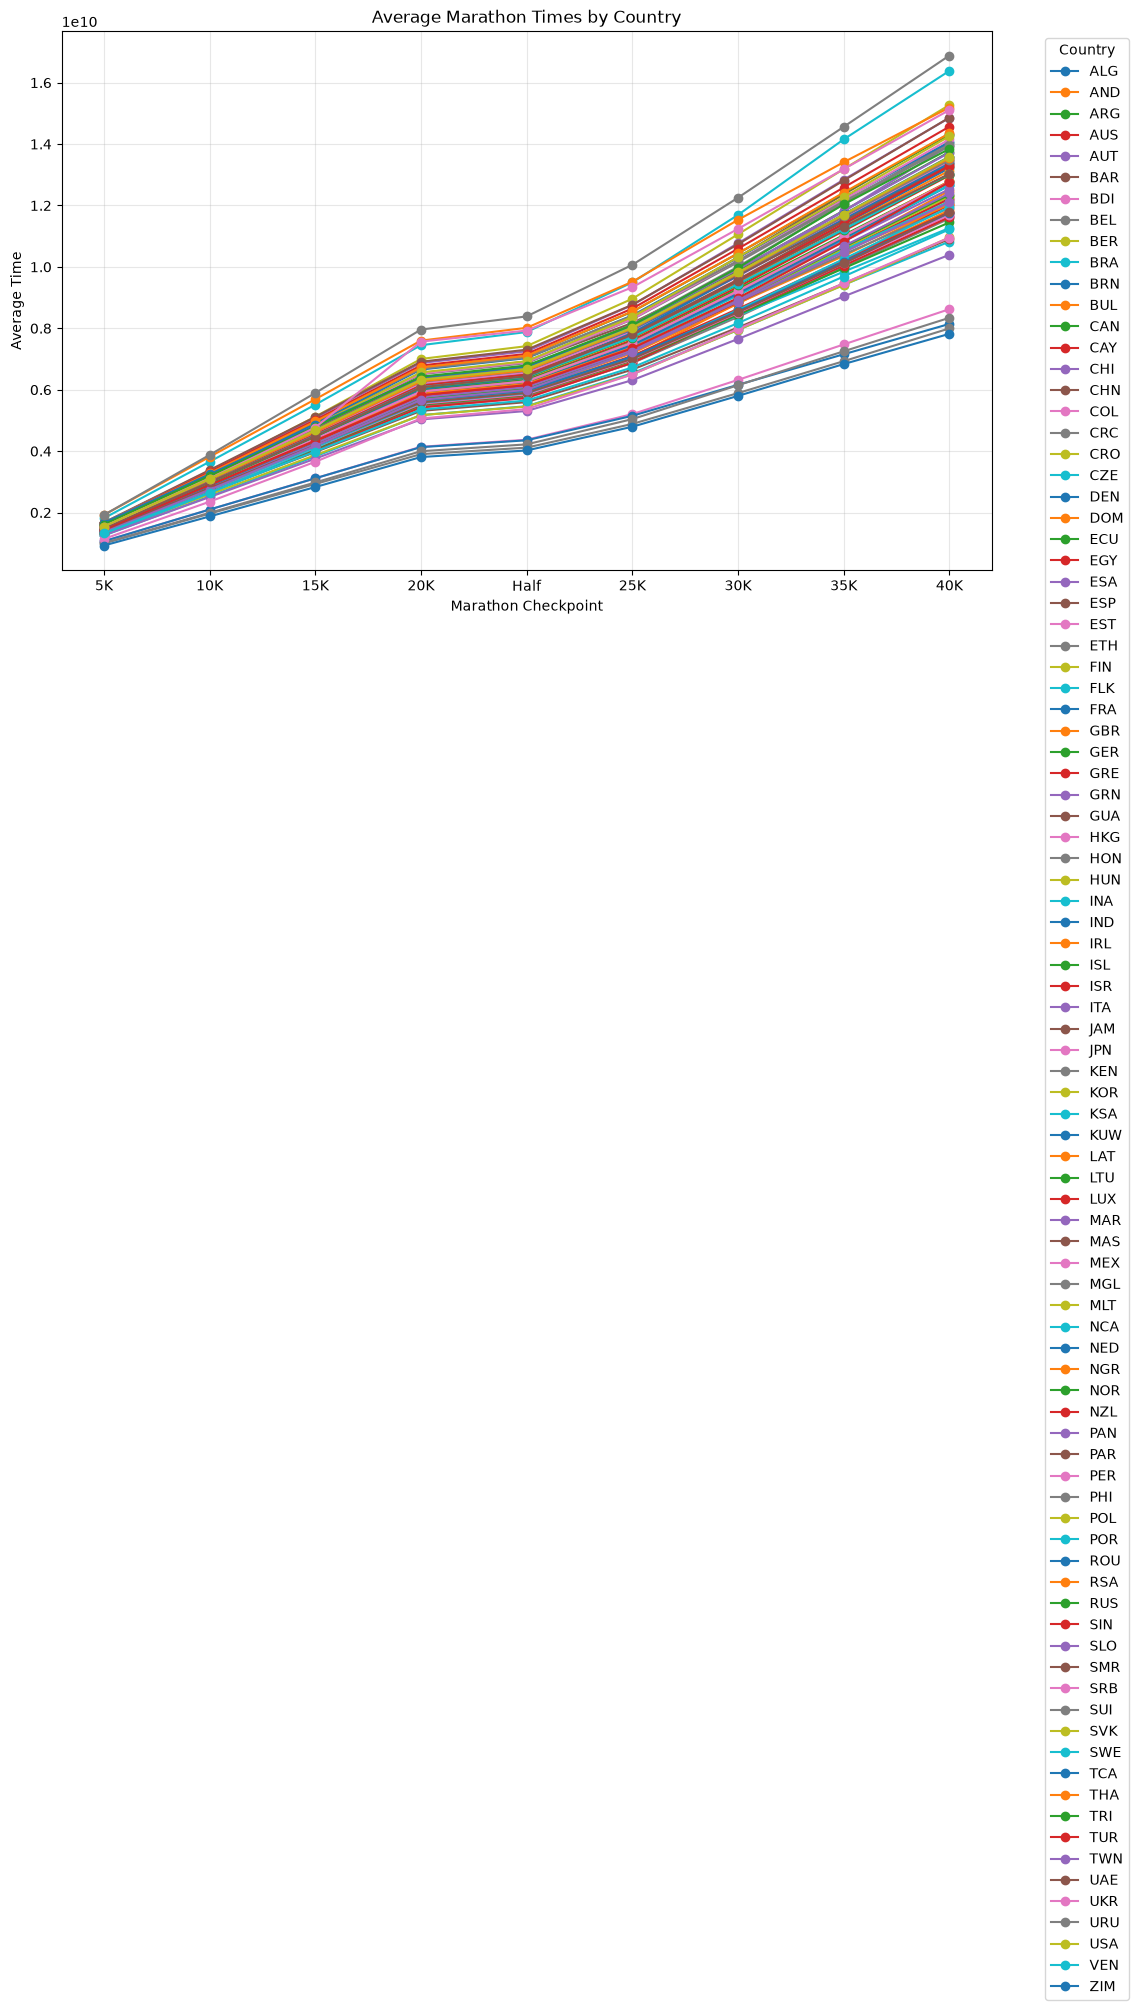

In [26]:
plt.figure(figsize=(12, 7))

for country in country_averages.index:
    plt.plot(
        checkpoints,
        country_averages.loc[country],
        marker='o',
        label=country
    )

plt.xlabel('Marathon Checkpoint')
plt.ylabel('Average Time')
plt.title('Average Marathon Times by Country')

plt.legend(title='Country', bbox_to_anchor=(1.05, 1),
           loc='upper left')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Overall it seems like each country uses a similar pacing strategy. However, there is some deviation where runners from some countries where they slow down more substantially at the end. There also appears to be a cluster of countries where the athletes start faster and remain faster throughout. Maybe some sort of clustering analysis could determine if there is a specific pacing strategy (slope) between two checkpionts that seems most effective

Need to identify which type of algorithm is most appropriate